# Practical 7 — Neural Style Transfer and GAN-Based Art

**Enrollment:** BT24S05F007

## Aim
Create an artistic image that keeps the layout of a content picture while borrowing the color pattern of a style picture, then compare that idea with a tiny GAN that paints new color textures.

## Neural style transfer idea
Optimize a canvas so its **content features** stay close to the content image and its **style statistics** stay close to the style image. Here the features are local patch means (content) and channel covariances (style), which is enough to show the trade-off without downloading a huge CNN.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)


## Synthetic content and style images


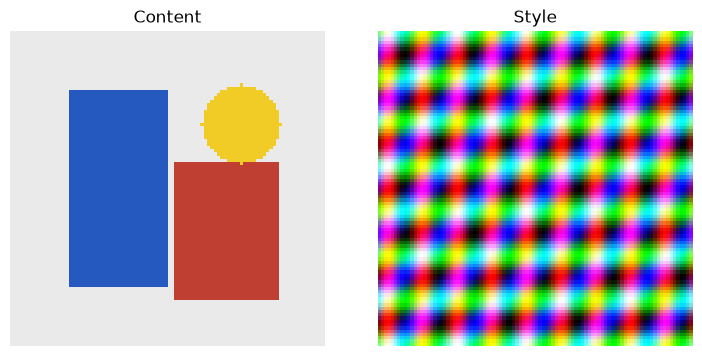

In [2]:
def make_content(size=96):
    img = np.full((size, size, 3), 0.92, dtype=np.float32)
    img[18:78, 18:48] = [0.15, 0.35, 0.75]
    img[40:82, 50:82] = [0.75, 0.25, 0.20]
    yy, xx = np.ogrid[:size, :size]
    disk = (xx - 70) ** 2 + (yy - 28) ** 2 <= 12 ** 2
    img[disk] = [0.95, 0.80, 0.15]
    return img

def make_style(size=96):
    yy, xx = np.meshgrid(np.linspace(0, 1, size), np.linspace(0, 1, size), indexing="ij")
    img = np.stack(
        [
            0.5 + 0.5 * np.sin(18 * np.pi * xx),
            0.5 + 0.5 * np.cos(14 * np.pi * yy),
            0.5 + 0.5 * np.sin(10 * np.pi * (xx + yy)),
        ],
        axis=-1,
    ).astype(np.float32)
    return img

content_np = make_content()
style_np = make_style()

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6))
axes[0].imshow(content_np)
axes[0].set_title("Content")
axes[0].axis("off")
axes[1].imshow(style_np)
axes[1].set_title("Style")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## Losses and optimization


In [3]:
def to_tensor(image):
    return torch.tensor(image, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0)

def patch_means(image, kernel=8):
    return F.avg_pool2d(image, kernel_size=kernel, stride=kernel)

def gram_matrix(image):
    b, c, h, w = image.shape
    flat = image.view(b, c, h * w)
    gram = torch.bmm(flat, flat.transpose(1, 2)) / (c * h * w)
    return gram

content = to_tensor(content_np)
style = to_tensor(style_np)
canvas = content.clone().requires_grad_(True)
optimizer = torch.optim.Adam([canvas], lr=0.08)

content_target = patch_means(content).detach()
style_target = gram_matrix(style).detach()
content_w, style_w = 1.0, 2500.0
history = []

for step in range(1, 251):
    optimizer.zero_grad()
    c_loss = F.mse_loss(patch_means(canvas), content_target)
    s_loss = F.mse_loss(gram_matrix(canvas), style_target)
    loss = content_w * c_loss + style_w * s_loss
    loss.backward()
    optimizer.step()
    with torch.no_grad():
        canvas.clamp_(0.0, 1.0)
    history.append(float(loss.item()))
    if step % 50 == 0:
        print(f"step {step:3d} | total {loss.item():.4f} | content {c_loss.item():.4f} | style {s_loss.item():.6f}")

styled = canvas.detach().squeeze(0).permute(1, 2, 0).cpu().numpy()


step  50 | total 0.1537 | content 0.0646 | style 0.000036
step 100 | total 0.1006 | content 0.0739 | style 0.000011
step 150 | total 0.0834 | content 0.0777 | style 0.000002
step 200 | total 0.0745 | content 0.0733 | style 0.000000
step 250 | total 0.0708 | content 0.0691 | style 0.000001


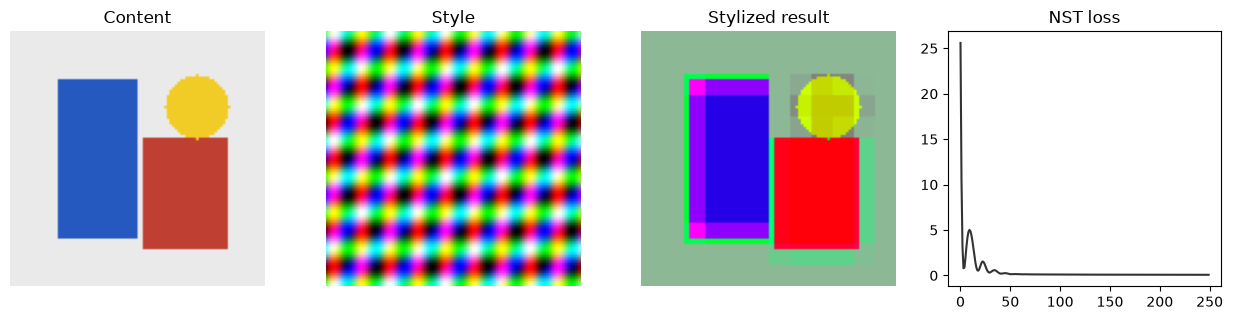

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.3))
axes[0].imshow(content_np)
axes[0].set_title("Content")
axes[1].imshow(style_np)
axes[1].set_title("Style")
axes[2].imshow(styled)
axes[2].set_title("Stylized result")
axes[3].plot(history, color="#333")
axes[3].set_title("NST loss")
for ax in axes[:3]:
    ax.axis("off")
plt.tight_layout()
plt.show()


## Tiny texture GAN
A second path to artistic content: a 1D noise → RGB texture generator trained against a discriminator that sees style-image patches.


texture GAN epoch 100 | D 0.114 | G 3.521


texture GAN epoch 200 | D 0.120 | G 4.149
texture GAN epoch 300 | D 0.018 | G 10.308
texture GAN epoch 400 | D 0.052 | G 10.253


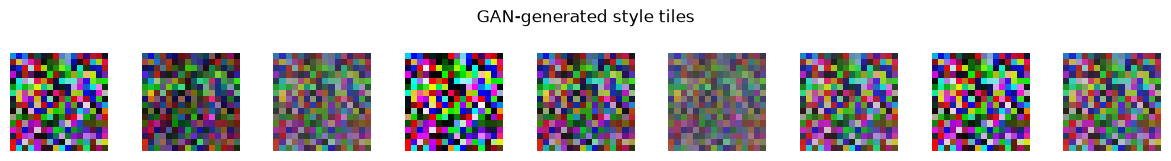

In [5]:
style_patches = []
img = style_np
for y in range(0, 96 - 16, 8):
    for x in range(0, 96 - 16, 8):
        style_patches.append(img[y:y + 16, x:x + 16].reshape(-1))
style_patches = np.asarray(style_patches, dtype=np.float32)
style_t = torch.tensor(style_patches)

class TextureGen(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(8, 64),
            nn.ReLU(),
            nn.Linear(64, 16 * 16 * 3),
            nn.Sigmoid(),
        )

    def forward(self, z):
        return self.net(z)

class TextureDisc(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(16 * 16 * 3, 64),
            nn.LeakyReLU(0.2),
            nn.Linear(64, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.net(x)

g = TextureGen()
d = TextureDisc()
opt_g = torch.optim.Adam(g.parameters(), lr=0.002)
opt_d = torch.optim.Adam(d.parameters(), lr=0.002)
bce = nn.BCELoss()

for epoch in range(1, 401):
    idx = torch.randint(0, style_t.shape[0], (32,))
    real = style_t[idx]
    z = torch.randn(32, 8)
    fake = g(z).detach()
    opt_d.zero_grad()
    d_loss = bce(d(real), torch.ones(32, 1)) + bce(d(fake), torch.zeros(32, 1))
    d_loss.backward()
    opt_d.step()
    z = torch.randn(32, 8)
    opt_g.zero_grad()
    g_loss = bce(d(g(z)), torch.ones(32, 1))
    g_loss.backward()
    opt_g.step()
    if epoch % 100 == 0:
        print(f"texture GAN epoch {epoch:3d} | D {d_loss.item():.3f} | G {g_loss.item():.3f}")

with torch.no_grad():
    tiles = g(torch.randn(9, 8)).view(9, 16, 16, 3).cpu().numpy()

fig, axes = plt.subplots(1, 9, figsize=(12, 1.6))
for ax, tile in zip(axes, tiles):
    ax.imshow(np.clip(tile, 0, 1))
    ax.axis("off")
plt.suptitle("GAN-generated style tiles")
plt.tight_layout()
plt.show()


## Conclusion
Neural style transfer edits one canvas until content structure and style statistics both match their targets. A GAN instead invents new patches from noise after competing with a discriminator. Together they show two generative routes to artistic images in PyTorch.


## Run results

Outputs captured from the executed notebook.

```
step  50 | total 0.1537 | content 0.0646 | style 0.000036
step 100 | total 0.1006 | content 0.0739 | style 0.000011
step 150 | total 0.0834 | content 0.0777 | style 0.000002
step 200 | total 0.0745 | content 0.0733 | style 0.000000
step 250 | total 0.0708 | content 0.0691 | style 0.000001
```

```
texture GAN epoch 100 | D 0.114 | G 3.521
texture GAN epoch 200 | D 0.120 | G 4.149
texture GAN epoch 300 | D 0.018 | G 10.308
texture GAN epoch 400 | D 0.052 | G 10.253
```

**figure 1**

![figure 1](results/GenAI_Practical_07_fig1.png)

**figure 2**

![figure 2](results/GenAI_Practical_07_fig2.png)

**figure 3**

![figure 3](results/GenAI_Practical_07_fig3.png)
